# 02 — Canonical Football Landscape: First Aligned Snapshot

**Research purpose:** Establish one defensible observation connecting a carrier, teammates, defenders, existing attacking options, engagement annotations, and contextual phase, **at the decision time**. This is a targeted P1 prototype, not the final H1–H3 model.

**Data restriction:** Only SkillCorner-provided local files; no outside match data or video. **Output convention:** every generated artifact goes into `outputs/` at the repository root. **Read-only inputs:** this notebook does not modify source data.

**What is not frozen yet:** causal interpretation of pressure, chain-level coordination, hypothetical carry dynamics, pose effect, and EPV labels. Official specification definitions still govern all category meanings.

## 1. Locate the data and output directory
This works when launching Jupyter either in the project directory or its `notebooks/` subdirectory. We first prototype on **one match** rather than processing all 20 matches before the join rules are validated.

In [1]:
from pathlib import Path
from collections import Counter
from datetime import datetime, timezone
import csv, json, sys

ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "data" / "matches").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Expected data/matches in the project root or one of its parent folders.")
OUTPUTS = ROOT / "outputs"
OUTPUTS.mkdir(parents=True, exist_ok=True)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
MATCH_ID = '1874553'  # illustrative match; avoid selecting on outcomes
FOLDER = ROOT / 'data' / 'matches' / MATCH_ID
print('Repository:', ROOT)
print('All notebook outputs:', OUTPUTS)
print('Illustrative match:', MATCH_ID)


Repository: /Users/fadihaddad/Documents/GitHub/SkillCorner_opendata_soccer
All notebook outputs: /Users/fadihaddad/Documents/GitHub/SkillCorner_opendata_soccer/outputs
Illustrative match: 1874553


## 2. Read the source event and phase tables
An event row is **not** an independent attacking decision or press episode. SkillCorner has four event types, with different field applicability. We avoid treating blank subtype fields on other event types as missing data errors.

In [2]:
def csv_records(path):
    with path.open('r', newline='', encoding='utf-8-sig') as handle:
        return list(csv.DictReader(handle))

events = csv_records(FOLDER / f'{MATCH_ID}_dynamic_events.csv')
phases = csv_records(FOLDER / f'{MATCH_ID}_phases_of_play.csv')
print('Events:', len(events), 'Phases:', len(phases))
print('Event types:', Counter(e['event_type'] for e in events))
print('Defending phases:', Counter(p['team_out_of_possession_phase_type'] for p in phases))


Events: 4915 Phases: 423
Event types: Counter({'passing_option': 2543, 'player_possession': 959, 'on_ball_engagement': 878, 'off_ball_run': 535})
Defending phases: Counter({'medium_block': 140, 'chaotic': 87, 'low_block': 82, 'high_block': 55, 'defending_direct': 32, 'defending_set_play': 15, 'defending_transition': 7, 'defending_quick_break': 5})


## 3. Align event moments to phases with period and tracking frame
Match ID, period and frame together determine the *temporal* join. A phase is an interval, not a row keyed by frame. We use interval membership and explicitly refuse ambiguous multiple matches.

**Caution:** Phase labels may summarize an entire phase. For real-time prediction at frame `t`, using a label inferred from later frames could leak future information. Here it is attached as an **analysis annotation**, not automatically accepted as a predictive feature.

In [3]:
def as_int(v):
    try: return int(v)
    except (TypeError, ValueError): return None

def phase_candidates(event, phase_rows):
    frame = as_int(event.get('frame_start'))
    period = as_int(event.get('period'))
    if frame is None or period is None: return []
    return [p for p in phase_rows
            if as_int(p.get('period')) == period
            and as_int(p.get('frame_start')) is not None
            and as_int(p.get('frame_end')) is not None
            and as_int(p['frame_start']) <= frame <= as_int(p['frame_end'])]

possessions = [e for e in events if e.get('event_type') == 'player_possession']
join_hist = Counter(len(phase_candidates(e, phases)) for e in possessions)
print('Matching phase intervals per player-possession event:', dict(sorted(join_hist.items())))
if join_hist.get(2, 0) or any(k > 1 for k in join_hist):
    print('CAUTION: some event starts match multiple phases; do not use the phase labels for these events.')


Matching phase intervals per player-possession event: {1: 827, 2: 132}
CAUTION: some event starts match multiple phases; do not use the phase labels for these events.


## 4. Build a small set of decision-time observation candidates
Each *player possession start* is a possible decision time. Related passing options and defender engagements are candidate context, not automatically contemporaneous: we include only events whose intervals cover the decision frame and report the counts. Actual temporal availability and field definitions require official specification confirmation.

We retain match ID in every key, as event IDs are only unique within match.

In [4]:
def covering(rows, period, frame):
    return [e for e in rows if as_int(e.get('period')) == period
            and as_int(e.get('frame_start')) is not None
            and as_int(e.get('frame_end')) is not None
            and as_int(e['frame_start']) <= frame <= as_int(e['frame_end'])]

passing = [e for e in events if e.get('event_type') == 'passing_option']
engagements = [e for e in events if e.get('event_type') == 'on_ball_engagement']
selected = possessions[:12]  # first chronological-looking rows; deterministic, not a sampled cohort
snapshots = []
for event in selected:
    frame, period = as_int(event.get('frame_start')), as_int(event.get('period'))
    if frame is None or period is None: continue
    ph = phase_candidates(event, phases)
    opts = covering(passing, period, frame)
    engs = covering(engagements, period, frame)
    snapshots.append({
        'match_id': MATCH_ID, 'period': period, 'tracking_frame': frame,
        'possession_event_id': event.get('event_id'),
        'carrier_player_id': event.get('player_id'),
        'phase_match_count': len(ph),
        'defending_phase_annotation': ph[0].get('team_out_of_possession_phase_type') if len(ph)==1 else None,
        'overlapping_passing_option_events': len(opts),
        'overlapping_on_ball_engagements': len(engs),
        'carry_realized_label': event.get('carry'), # post-action label; never a pre-action feature
    })
for row in snapshots[:5]: print(row)


{'match_id': '1874553', 'period': 1, 'tracking_frame': 29, 'possession_event_id': '8_0', 'carrier_player_id': '50973', 'phase_match_count': 1, 'defending_phase_annotation': 'medium_block', 'overlapping_passing_option_events': 0, 'overlapping_on_ball_engagements': 0, 'carry_realized_label': 'False'}
{'match_id': '1874553', 'period': 1, 'tracking_frame': 42, 'possession_event_id': '8_1', 'carrier_player_id': '51050', 'phase_match_count': 1, 'defending_phase_annotation': 'medium_block', 'overlapping_passing_option_events': 2, 'overlapping_on_ball_engagements': 0, 'carry_realized_label': 'True'}
{'match_id': '1874553', 'period': 1, 'tracking_frame': 102, 'possession_event_id': '8_2', 'carrier_player_id': '50966', 'phase_match_count': 1, 'defending_phase_annotation': 'medium_block', 'overlapping_passing_option_events': 0, 'overlapping_on_ball_engagements': 0, 'carry_realized_label': 'True'}
{'match_id': '1874553', 'period': 1, 'tracking_frame': 162, 'possession_event_id': '8_3', 'carrier_pl

## 5. Read tracking only at chosen frames
Tracking is a JSONL stream at 10 fps. We stream **one match once**, keeping just the frames corresponding to these example decisions. No pose archive needs to be loaded. The player's x/y values are pitch-centered metres according to SkillCorner's schema; do not merge them directly with dynamic-event x/y without checking normalization.

In [5]:
needed = {r['tracking_frame'] for r in snapshots}
tracking_at = {}
trackpath = FOLDER / f'{MATCH_ID}_tracking_extrapolated.jsonl'
with trackpath.open('r', encoding='utf-8') as f:
    for line in f:
        obj = json.loads(line)
        frame = as_int(obj.get('frame'))
        if frame in needed:
            tracking_at[frame] = obj
            if len(tracking_at) == len(needed): break
for r in snapshots:
    fr = tracking_at.get(r['tracking_frame'])
    r['tracking_frame_found'] = fr is not None and as_int(fr.get('period')) == r['period']
    r['tracking_players_total'] = len(fr.get('player_data') or []) if r['tracking_frame_found'] else None
    r['tracking_players_detected'] = sum(p.get('is_detected') is True for p in (fr.get('player_data') or [])) if r['tracking_frame_found'] else None
    r['carrier_in_tracking_frame'] = (any(str(p.get('player_id')) == str(r['carrier_player_id']) for p in (fr.get('player_data') or [])) if r['tracking_frame_found'] else None)
print('Exact tracking-frame hits:', sum(r['tracking_frame_found'] for r in snapshots), '/', len(snapshots))
print('Carrier ID in exact tracking frame:', sum(r['carrier_in_tracking_frame'] is True for r in snapshots), '/', len(snapshots))


Exact tracking-frame hits: 12 / 12
Carrier ID in exact tracking frame: 12 / 12


## 5a. Targeted spatial and boundary diagnostics
This checks **coordinate availability and detection separately**. IDs are not proof of usable geometry. It also tests whether the double-phase joins occur **only at shared boundaries**. No underlying data is modified; the original ambiguous events remain unassigned until documented boundary semantics are confirmed.

In [6]:
# Count phase ambiguities that are exactly shared endpoints (candidate explanation, not a fix).
ambiguous = []
for e in possessions:
    candidates = phase_candidates(e, phases)
    if len(candidates) != 2: continue
    t = as_int(e['frame_start'])
    shared_boundary = any(as_int(p.get('frame_end')) == t for p in candidates) and any(
        as_int(p.get('frame_start')) == t for p in candidates)
    ambiguous.append(shared_boundary)
print('Multiple phase joins:', len(ambiguous))
print('Exactly shared end/start boundary:', sum(ambiguous))
print('Other ambiguities:', len(ambiguous) - sum(ambiguous))

def finite_xy(item):
    import math
    try:
        return all(math.isfinite(float(item[k])) for k in ('x', 'y'))
    except (ValueError, TypeError, KeyError):
        return False

for r in snapshots:
    if not r['tracking_frame_found']:
        r.update(carrier_detected=None,carrier_finite_xy=None,ball_finite_xy=None,
                 ball_detected=None,players_finite_xy=None,players_detected_finite_xy=None)
        continue
    fr=tracking_at[r['tracking_frame']]
    players=fr.get('player_data') or []
    carrier=next((p for p in players if str(p.get('player_id'))==str(r['carrier_player_id'])),None)
    ball=fr.get('ball_data') or {}
    r['carrier_detected']=carrier.get('is_detected') if carrier else None
    r['carrier_finite_xy']=finite_xy(carrier) if carrier else False
    r['ball_detected']=ball.get('is_detected')
    r['ball_finite_xy']=finite_xy(ball)
    r['players_finite_xy']=sum(finite_xy(p) for p in players)
    r['players_detected_finite_xy']=sum(p.get('is_detected') is True and finite_xy(p) for p in players)
for r in snapshots:
    print('frame',r['tracking_frame'], 'carrier detected',r['carrier_detected'],
          'carrier XY',r['carrier_finite_xy'],'ball detected',r['ball_detected'],
          'ball XY',r['ball_finite_xy'],'players detected+XY',r['players_detected_finite_xy'])

Multiple phase joins: 132
Exactly shared end/start boundary: 132
Other ambiguities: 0
frame 29 carrier detected True carrier XY True ball detected True ball XY True players detected+XY 18
frame 42 carrier detected True carrier XY True ball detected True ball XY True players detected+XY 18
frame 102 carrier detected True carrier XY True ball detected True ball XY True players detected+XY 18
frame 162 carrier detected True carrier XY True ball detected True ball XY True players detected+XY 12
frame 182 carrier detected True carrier XY True ball detected True ball XY True players detected+XY 14
frame 257 carrier detected True carrier XY True ball detected True ball XY True players detected+XY 4
frame 291 carrier detected True carrier XY True ball detected True ball XY True players detected+XY 8
frame 305 carrier detected True carrier XY True ball detected True ball XY True players detected+XY 10
frame 320 carrier detected True carrier XY True ball detected True ball XY True players detect

## 6. Inspect one actual football snapshot
This is a **descriptive** spatial view, not a trained space-control model. It plots all tracked players in pitch-centered metres and the tracked ball when available. The plot is saved only under `outputs/`. Player colours are not used to imply team assignments until metadata join is explicitly established.

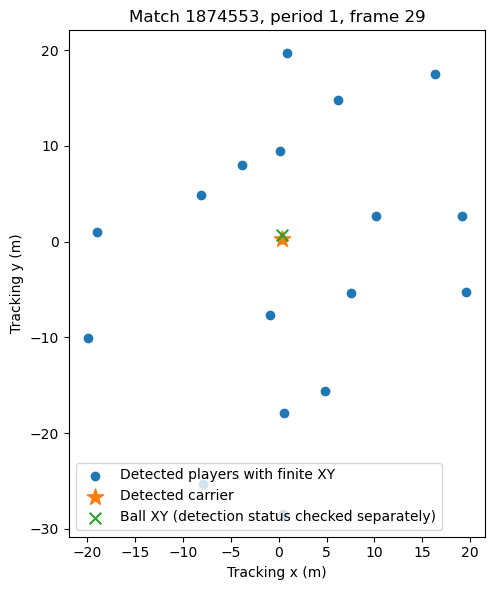

Saved: /Users/fadihaddad/Documents/GitHub/SkillCorner_opendata_soccer/outputs/P1_example_tracking_snapshot_verified.png


In [7]:
try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None
    print('matplotlib unavailable: skipping figure; JSON output still works.')
if plt and snapshots:
    # Prefer a frame with a uniquely assigned phase and an observed carrier and ball.
    candidates = [r for r in snapshots if r['tracking_frame_found']
                  and r['phase_match_count'] == 1
                  and r['carrier_detected'] is True and r['carrier_finite_xy']
                  and r['ball_finite_xy'] and r['players_detected_finite_xy'] >= 10]
    if not candidates:
        print('No qualifying snapshot; do not substitute an unverified plot.')
    else:
        r = candidates[0]
        fr=tracking_at[r['tracking_frame']]
        players=fr.get('player_data') or []
        observed=[p for p in players if p.get('is_detected') is True and finite_xy(p)]
        fig, ax = plt.subplots(figsize=(10, 6))
        ax.scatter([float(p['x']) for p in observed], [float(p['y']) for p in observed],
                   label='Detected players with finite XY')
        carrier=next(p for p in players if str(p.get('player_id'))==str(r['carrier_player_id']))
        ax.scatter([float(carrier['x'])],[float(carrier['y'])],marker='*',s=150,
                   label='Detected carrier')
        ball=fr.get('ball_data') or {}
        ax.scatter([float(ball['x'])],[float(ball['y'])],marker='x',s=70,
                   label='Ball XY (detection status checked separately)')
        ax.set_aspect('equal',adjustable='box')
        ax.set_xlabel('Tracking x (m)'); ax.set_ylabel('Tracking y (m)')
        ax.set_title(f'Match {MATCH_ID}, period {r["period"]}, frame {r["tracking_frame"]}')
        ax.legend()
        fig.tight_layout()
        png=OUTPUTS/'P1_example_tracking_snapshot_verified.png'
        fig.savefig(png,dpi=150)
        plt.show()
        print('Saved:',png)


## 7. Save **lightweight derived outputs** and evaluate the gate
We export only 12 example summary records (no complete raw tracking or match data) and a simple gate summary to `outputs/`. **No pass here certifies full database accuracy.** The next scientific step is to verify exact event/phase definitions, finalize selection rules, and then scale the canonical architecture to all 20 matches.

In [8]:
gate = {
    'generated_utc': datetime.now(timezone.utc).isoformat(),
    'match_id': MATCH_ID,
    'sampled_possessions': len(snapshots),
    'phase_matches_per_possession_all': dict(sorted(join_hist.items())),
    'sample_exact_tracking_frame_hits': sum(x['tracking_frame_found'] for x in snapshots),
    'sample_carrier_id_hits': sum(x['carrier_in_tracking_frame'] is True for x in snapshots),
    'notes': [
        'Prototype only; no causal/predictive claims.',
        'Phase annotation is not automatically a real-time feature.',
        'carry_realized_label is an observed action, not a pre-action opportunity.',
        'Dynamic-event XY and tracking XY need documented coordinate alignment before pooling.',
    ],
}
gate['boundary_ambiguities_total'] = len(ambiguous)
gate['boundary_ambiguities_at_shared_endpoint'] = sum(ambiguous)
gate['sample_carriers_detected'] = sum(x['carrier_detected'] is True for x in snapshots)
gate['sample_carriers_finite_xy'] = sum(x['carrier_finite_xy'] is True for x in snapshots)
gate['sample_ball_finite_xy'] = sum(x['ball_finite_xy'] is True for x in snapshots)
out = OUTPUTS / 'P1_landscape_probe_REVISED.json'
out.write_text(json.dumps({'gate': gate, 'example_decisions': snapshots}, indent=2), encoding='utf-8')
print('Saved:', out)
print('Gate:', json.dumps(gate, indent=2))


Saved: /Users/fadihaddad/Documents/GitHub/SkillCorner_opendata_soccer/outputs/P1_landscape_probe_REVISED.json
Gate: {
  "generated_utc": "2026-10-24T23:03:00.171243+00:00",
  "match_id": "1874553",
  "sampled_possessions": 12,
  "phase_matches_per_possession_all": {
    "1": 827,
    "2": 132
  },
  "sample_exact_tracking_frame_hits": 12,
  "sample_carrier_id_hits": 12,
  "notes": [
    "Prototype only; no causal/predictive claims.",
    "Phase annotation is not automatically a real-time feature.",
    "carry_realized_label is an observed action, not a pre-action opportunity.",
    "Dynamic-event XY and tracking XY need documented coordinate alignment before pooling."
  ],
  "boundary_ambiguities_total": 132,
  "boundary_ambiguities_at_shared_endpoint": 132,
  "sample_carriers_detected": 11,
  "sample_carriers_finite_xy": 12,
  "sample_ball_finite_xy": 12
}


## 8. Interpretation and stopping rule
- **Pass if:** sample event starts can be matched to exactly one phase and an exact tracking frame with the intended carrier in most example observations; failures are documented for targeted resolution rather than dismissed.
- **Do not proceed to a predictive experiment until:** documented field definitions and temporal/coordinate semantics are reconciled, source-inferred labels are separated from decision-time features, and episode units are specified.
- **Next:** build reusable canonical loader, add explicit player-team role mapping, assign unique possession/episode keys, and use match-grouped validation. For carrying, model hypothetical actions separately from the realized `carry` label.

**Research interpretation:** A basic data join is the foundation of the football landscape; it is not the finished landscape itself.